In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 23
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [2]:
BLUE, TEAL, AMBER, CORAL = "#2F5D8C", "#2A9D8F", "#E9A23B", "#D1603D"
SLATE = "#2B3A4A"
PALETTE = [BLUE, TEAL, AMBER, CORAL]

sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#B8C2CC",
        "grid.color": "#E6EAEE",
        "axes.titleweight": "bold",
        "axes.titlecolor": SLATE,
        "axes.labelcolor": SLATE,
        "text.color": SLATE,
        "xtick.color": SLATE,
        "ytick.color": SLATE,
    },
)

In [3]:
df = pd.read_csv("../data/train-test.csv")
print(df.shape)
df.head()

(48000, 14)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [5]:
print("Unique values per column:")
print(df.nunique())

Unique values per column:
load_id         48000
pickup             64
delivery           64
pickup_lat         64
pickup_lon         63
delivery_lat       64
delivery_lon       63
distance        21204
equipment           3
weight          23678
date              304
market_index    32884
quote_signal    37633
posted_rate     45398
dtype: int64


In [6]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
print()
print((missing / len(df) * 100).round(2).astype(str) + " %")

market_index    374
weight          300
dtype: int64

market_index    0.78 %
weight          0.62 %
dtype: object


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


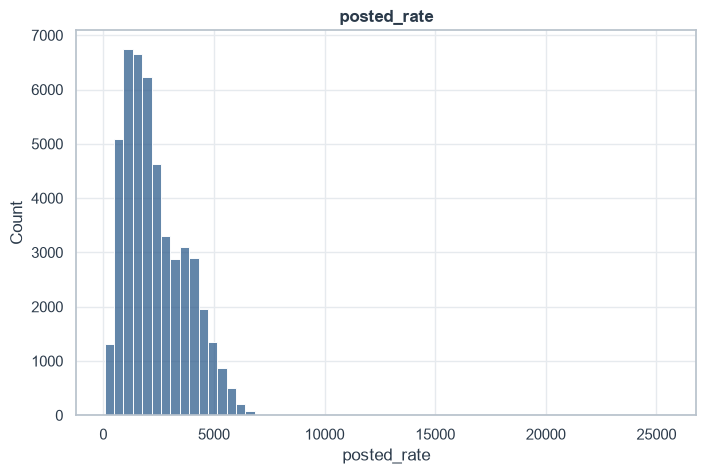

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["posted_rate"], bins=60, color=BLUE)
plt.title("posted_rate")
plt.show()

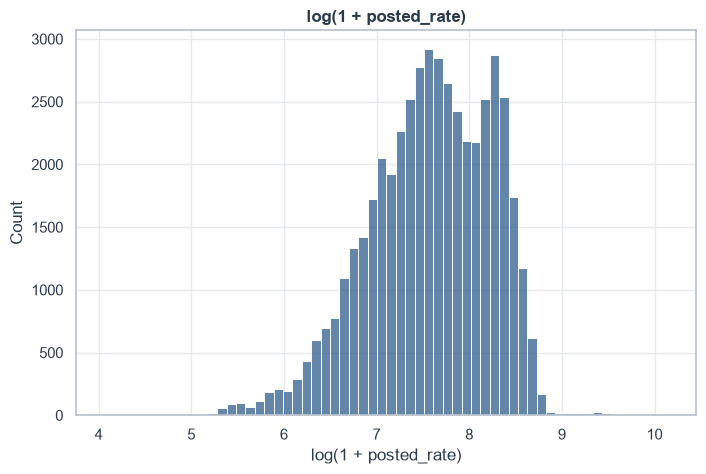

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df["posted_rate"]), bins=60, color=BLUE)
plt.title("log(1 + posted_rate)")
plt.xlabel("log(1 + posted_rate)")
plt.show()

In [10]:
df["posted_rate"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99, 0.999])

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
1%         327.168800
25%       1251.555000
50%       2030.760000
75%       3330.750000
99%       5972.834000
99.9%    12854.561710
max      25533.000000
Name: posted_rate, dtype: float64

## Features vs Target

In [11]:
df["rate_per_mile"] = df["posted_rate"] / df["distance"]  
sample = df.sample(5000, random_state=SEED)
df[["posted_rate", "distance", "rate_per_mile"]].describe().T

,count,mean,std,min,25%,50%,75%,max
posted_rate,48000.0,2373.980682,1486.493245,57.220000,1251.555000,2030.760000,3330.750000,25533.000000
distance,48000.0,1135.856654,728.564416,70.000000,550.400000,953.300000,1645.525000,3439.800000
rate_per_mile,48000.0,2.215347,0.583887,0.333709,1.986974,2.145348,2.342696,14.125294


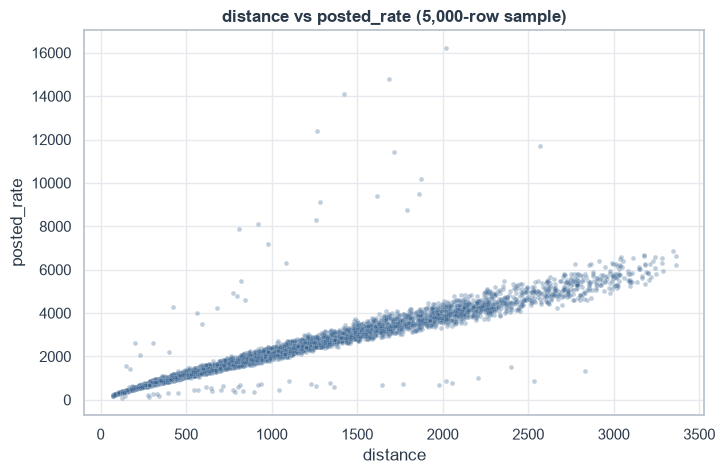

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="distance", y="posted_rate", color=BLUE, alpha=0.3, s=12)
plt.title("distance vs posted_rate (5,000-row sample)")
plt.show()

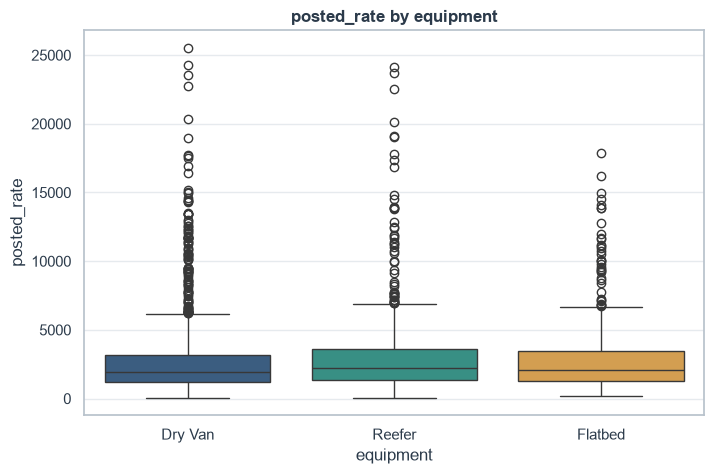

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="equipment", y="posted_rate", hue="equipment", palette=PALETTE[:3], legend=False)
plt.title("posted_rate by equipment")
plt.show()

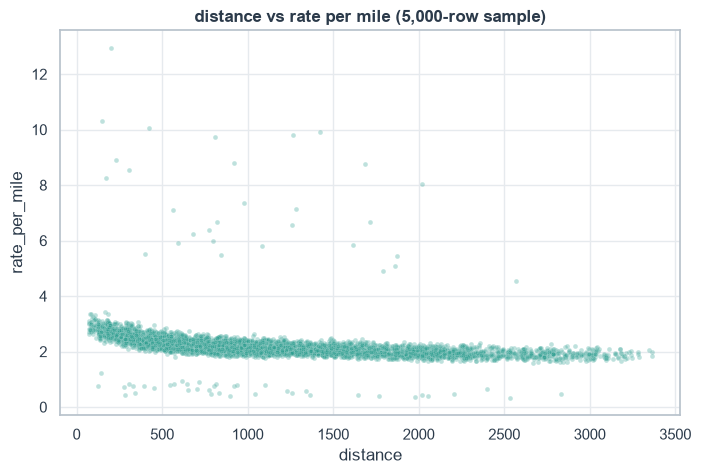

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="distance", y="rate_per_mile", color=TEAL, alpha=0.3, s=12)
plt.title("distance vs rate per mile (5,000-row sample)")
plt.show()

In [15]:
df.groupby("equipment")[["posted_rate", "rate_per_mile"]].median()

,posted_rate,rate_per_mile
equipment,,
Dry Van,1953.035,2.046203
Flatbed,2076.810,2.219683
Reefer,2196.670,2.311540


## Outliers

In [16]:
print(df["weight"].describe())
print()
print("Negative weights:", (df["weight"] < 0).sum())
print("Zero weights:", (df["weight"] == 0).sum())
print("Rows at the maximum weight:", (df["weight"] == df["weight"].max()).sum())

count    47700.000000
mean     31028.844004
std       9391.440620
min     -47500.000000
25%      25800.000000
50%      31436.500000
75%      37018.000000
max      47500.000000
Name: weight, dtype: float64

Negative weights: 292
Zero weights: 0
Rows at the maximum weight: 1191


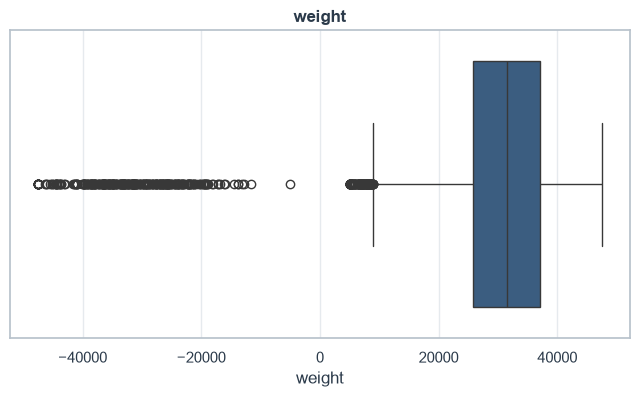

In [17]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["weight"], color=BLUE)
plt.title("weight")
plt.show()

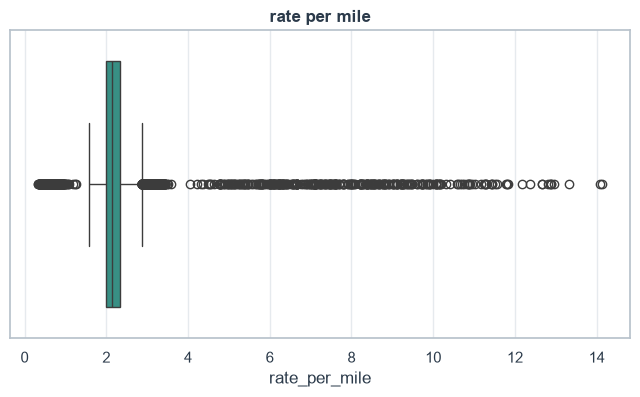

In [18]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["rate_per_mile"], color=TEAL)
plt.title("rate per mile")
plt.show()

In [19]:
q1, q3 = df["rate_per_mile"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

mask = (df["rate_per_mile"] < low) | (df["rate_per_mile"] > high)
print(f"Whisker limits: {low:.2f} to {high:.2f}")
print(f"Flagged rows: {mask.sum()} ({mask.mean() * 100:.2f} %)")

df.loc[mask].sort_values("rate_per_mile", ascending=False)[
    ["load_id", "pickup", "delivery", "distance", "equipment", "weight", "date", "posted_rate", "rate_per_mile"]
].head(10)

Whisker limits: 1.45 to 2.88
Flagged rows: 1634 (3.40 %)


,load_id,pickup,delivery,distance,equipment,weight,date,posted_rate,rate_per_mile
22254,TR-022255,Greensboro,Cincinnati,314.7,Reefer,-36485.0,2025-05-21,4445.23,14.125294
36609,TR-036610,Chattanooga,Atlanta,98.4,Reefer,22226.0,2025-08-20,1386.42,14.089634
870,TR-000871,Tulsa,Baton Rouge,305.6,Reefer,26447.0,2025-01-06,4069.24,13.315576
17070,TR-017071,Toledo,Dayton,201.5,Flatbed,38714.0,2025-04-18,2609.34,12.949578
27969,TR-027970,Buffalo,Boston,589.9,Reefer,24951.0,2025-06-25,7597.52,12.879335
23369,TR-023370,Amarillo,Lubbock,412.4,Flatbed,35494.0,2025-05-28,5308.96,12.873327
28012,TR-028013,Montgomery,Houston,604.3,Reefer,39690.0,2025-06-25,7773.37,12.863429
45483,TR-045484,Greensboro,Columbia,153.8,Dry Van,34198.0,2025-10-15,1971.21,12.816710
1415,TR-001416,Montgomery,Birmingham,198.2,Reefer,25383.0,2025-01-09,2509.96,12.663774
21968,TR-021969,Jacksonville,Columbia,254.5,Dry Van,32993.0,2025-05-19,3220.66,12.654853


## Correlation matrix and pair plot

In [20]:
num_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "distance",
            "weight", "market_index", "quote_signal", "posted_rate", "rate_per_mile"]
corr = df[num_cols].corr()
corr.round(2)

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate,rate_per_mile
pickup_lat,1.00,0.56,-0.01,-0.01,-0.08,0.00,-0.00,-0.00,-0.09,-0.03
pickup_lon,0.56,1.00,-0.01,-0.01,-0.27,0.01,0.00,0.01,-0.26,0.05
delivery_lat,-0.01,-0.01,1.00,0.56,-0.08,-0.00,-0.00,-0.00,-0.09,-0.03
delivery_lon,-0.01,-0.01,0.56,1.00,-0.28,-0.00,-0.01,0.01,-0.26,0.05
distance,-0.08,-0.27,-0.08,-0.28,1.00,0.00,-0.00,-0.06,0.91,-0.33
weight,0.00,0.01,-0.00,-0.00,0.00,1.00,-0.00,0.01,0.03,0.07
market_index,-0.00,0.00,-0.00,-0.01,-0.00,-0.00,1.00,-0.07,0.03,0.08
quote_signal,-0.00,0.01,-0.00,0.01,-0.06,0.01,-0.07,1.00,-0.04,0.05
posted_rate,-0.09,-0.26,-0.09,-0.26,0.91,0.03,0.03,-0.04,1.00,0.00
rate_per_mile,-0.03,0.05,-0.03,0.05,-0.33,0.07,0.08,0.05,0.00,1.00


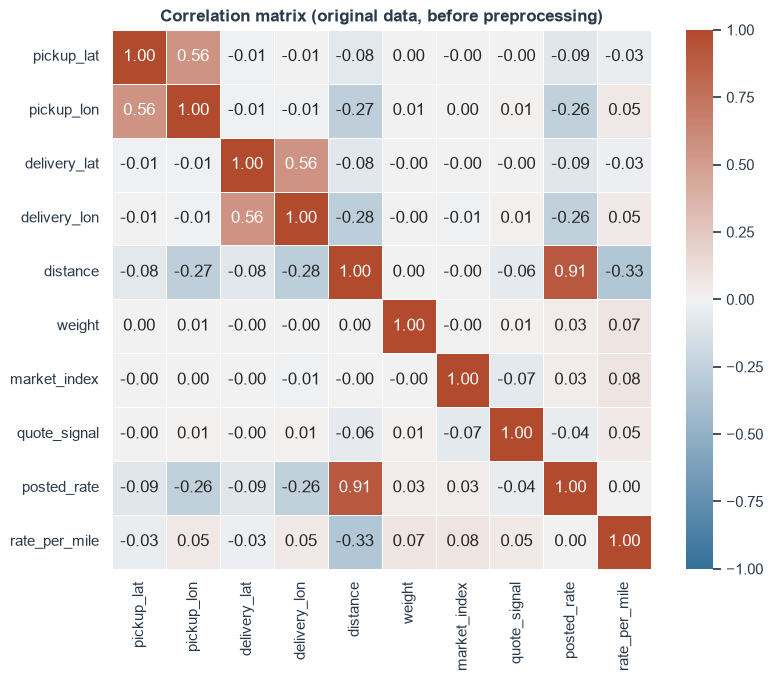

In [21]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(240, 20, s=80, l=45, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=0.5, square=True)
plt.title("Correlation matrix (original data, before preprocessing)")
plt.show()

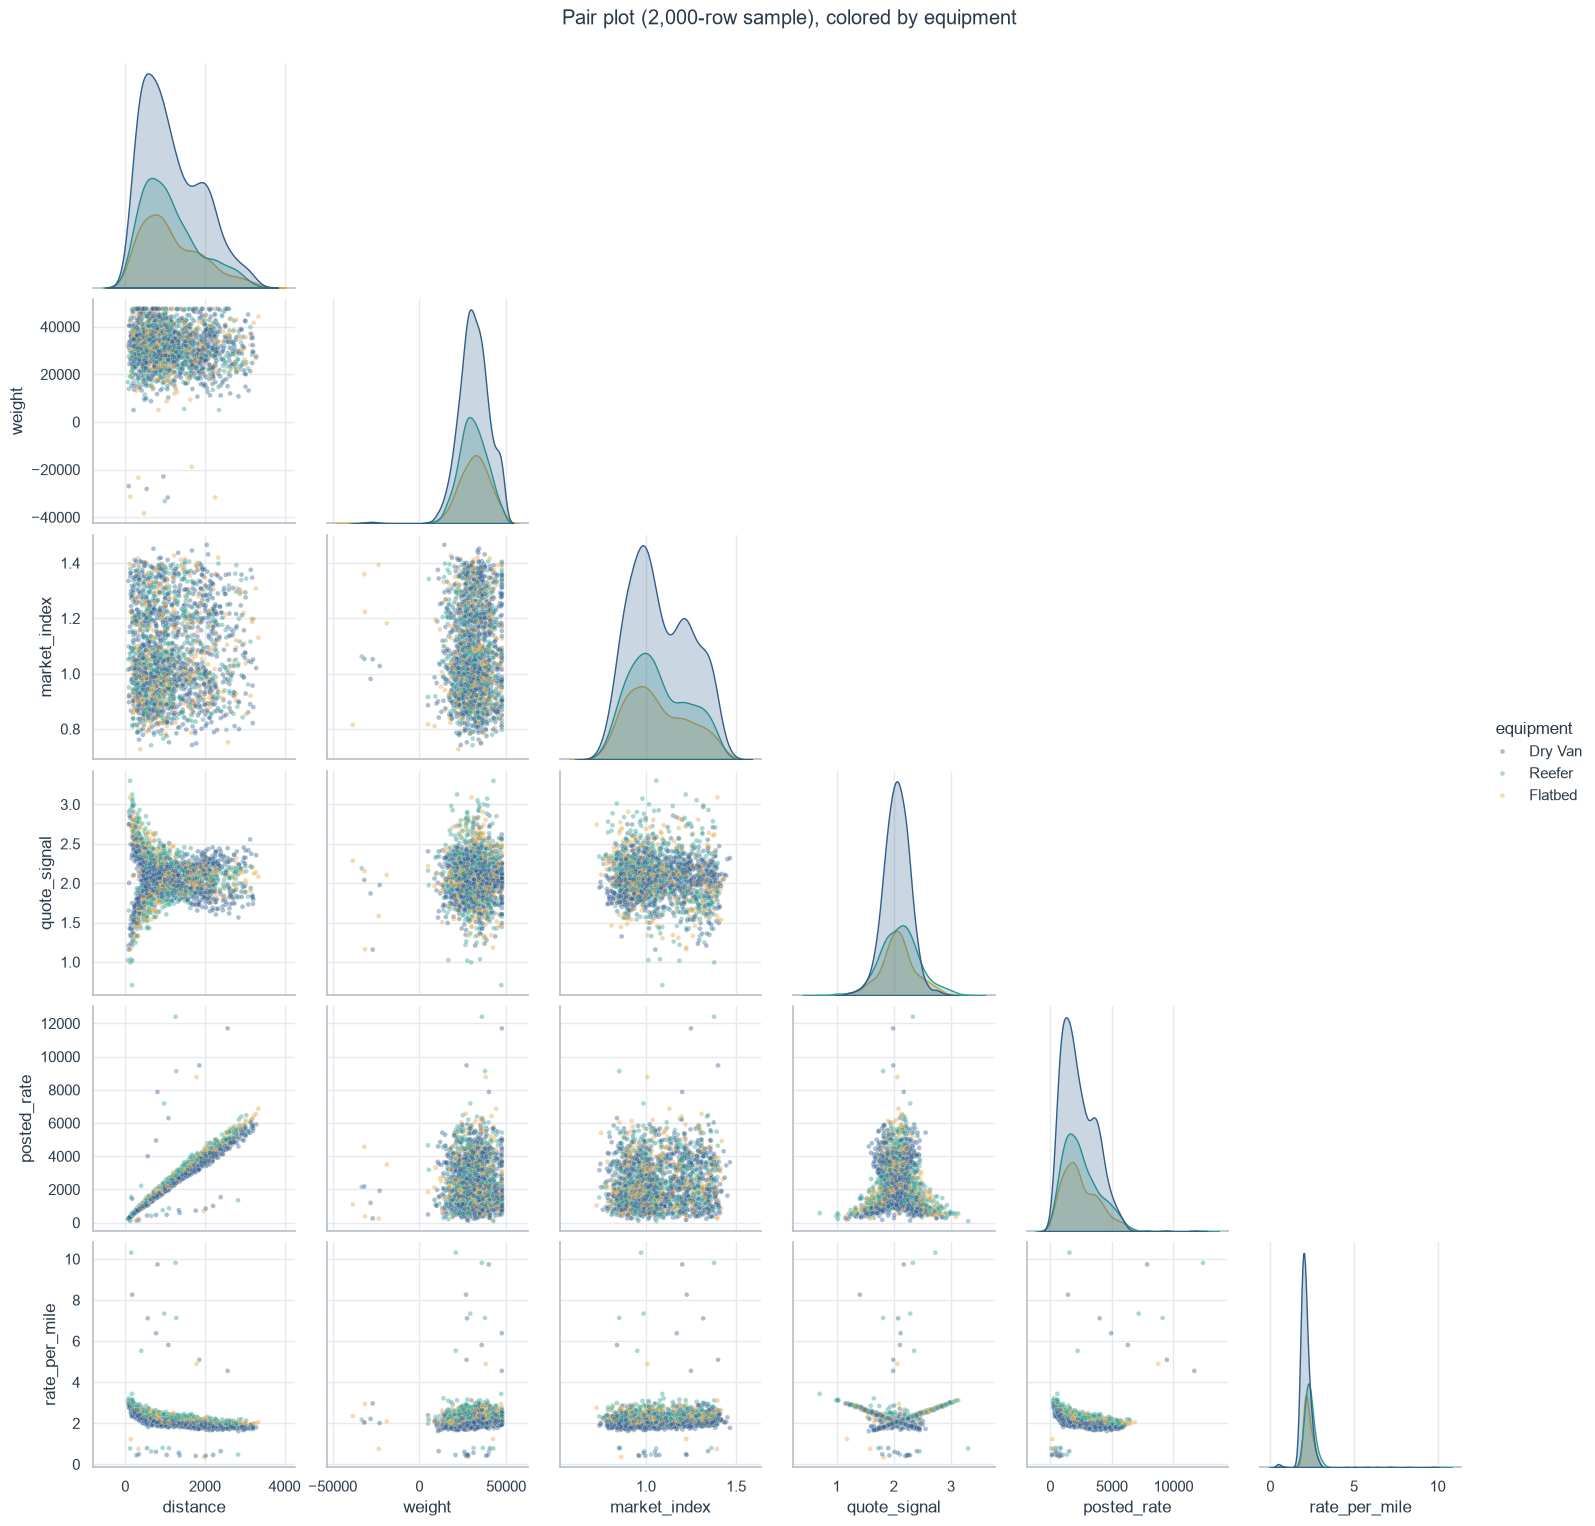

In [22]:
pair_cols = ["distance", "weight", "market_index", "quote_signal", "posted_rate", "rate_per_mile"]
pair_sample = df.sample(2000, random_state=SEED)

g = sns.pairplot(pair_sample, vars=pair_cols, hue="equipment", palette=PALETTE[:3],
                 plot_kws={"alpha": 0.4, "s": 12}, corner=True)
g.figure.suptitle("Pair plot (2,000-row sample), colored by equipment", y=1.02)
plt.show()

## Dates

In [23]:
df["date"] = pd.to_datetime(df["date"])

print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Unique dates:", df["date"].nunique())
print("Days in that range:", (df["date"].max() - df["date"].min()).days + 1)

daily = df.groupby("date")[["posted_rate", "rate_per_mile", "market_index", "quote_signal"]].mean()
print("Loads per day (min / mean / max):", df.groupby("date").size().agg(["min", "mean", "max"]).round(0).tolist())
daily.head()

Date range: 2025-01-01 to 2025-10-31
Unique dates: 304
Days in that range: 304
Loads per day (min / mean / max): [115.0, 158.0, 198.0]


,posted_rate,rate_per_mile,market_index,quote_signal
date,,,,
2025-01-01,2182.959586,2.043431,0.961224,2.052912
2025-01-02,2223.485595,2.053642,0.986606,2.067495
2025-01-03,2331.391154,2.068042,0.940339,2.051359
2025-01-04,2334.728782,2.050203,0.857702,2.038972
2025-01-05,2041.046688,2.077002,0.801855,2.078432


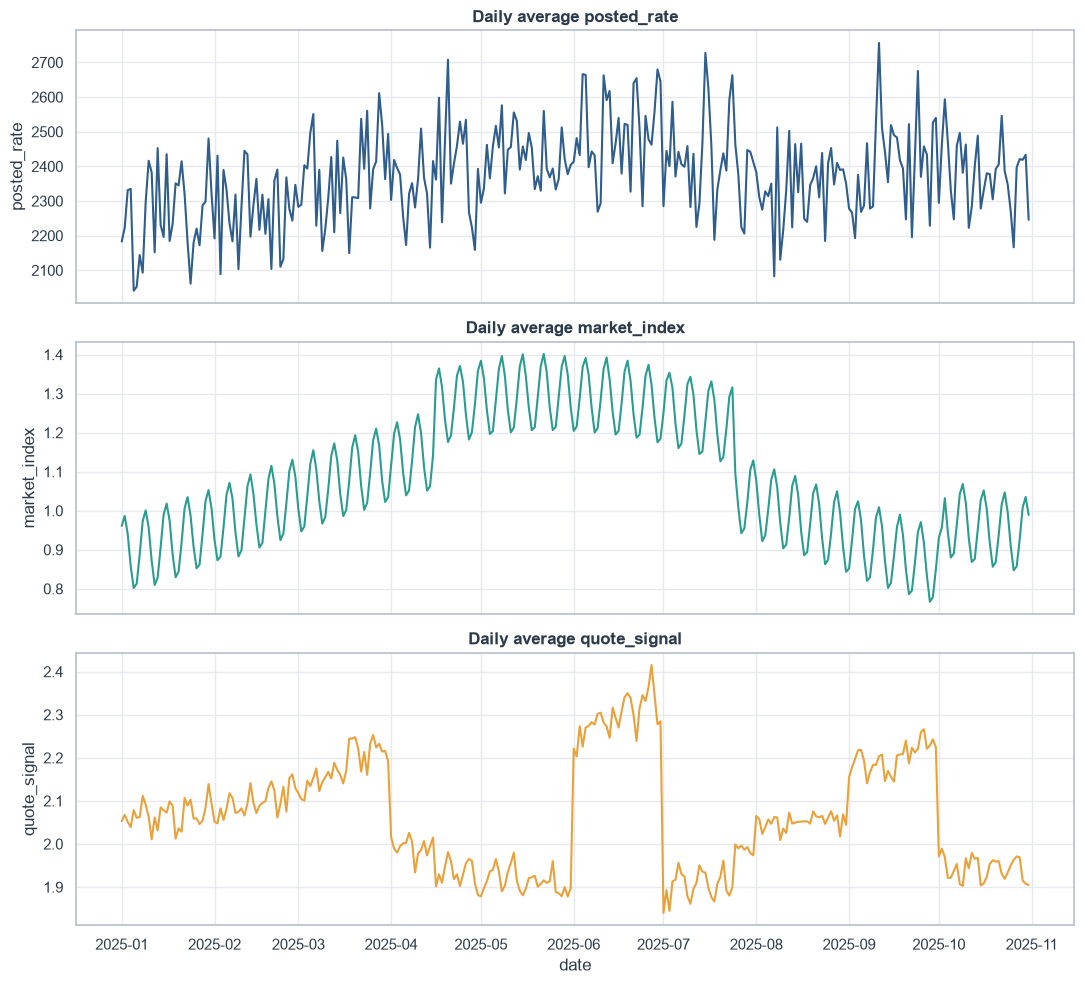

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

sns.lineplot(data=daily, x=daily.index, y="posted_rate", color=BLUE, ax=axes[0])
axes[0].set_title("Daily average posted_rate")

sns.lineplot(data=daily, x=daily.index, y="market_index", color=TEAL, ax=axes[1])
axes[1].set_title("Daily average market_index")

sns.lineplot(data=daily, x=daily.index, y="quote_signal", color=AMBER, ax=axes[2])
axes[2].set_title("Daily average quote_signal")
axes[2].set_xlabel("date")

plt.tight_layout()
plt.show()

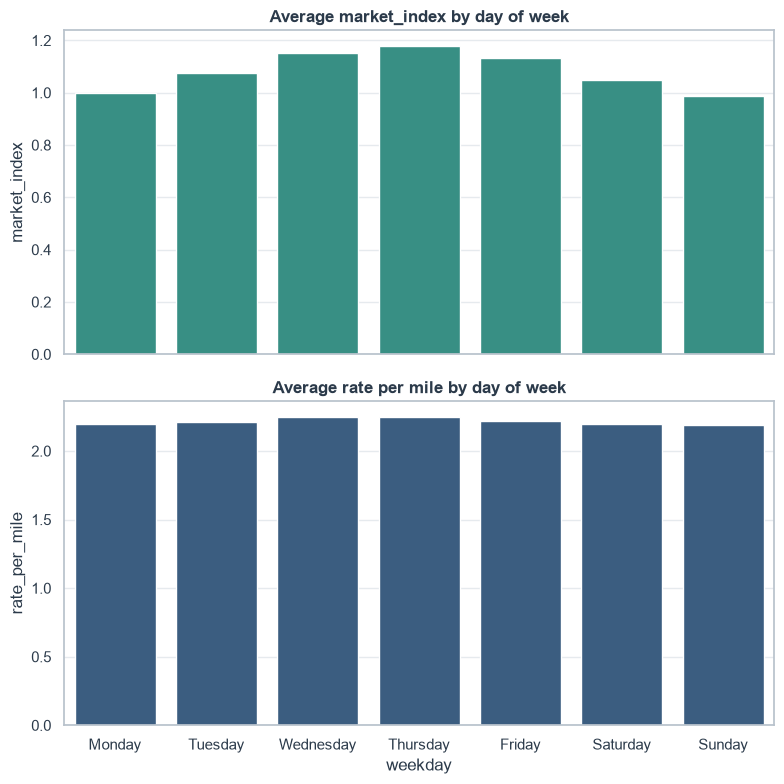

In [25]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["weekday"] = df["date"].dt.day_name()  # exploration only

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

sns.barplot(data=df, x="weekday", y="market_index", order=order, color=TEAL, errorbar=None, ax=axes[0])
axes[0].set_title("Average market_index by day of week")
axes[0].set_xlabel("")

sns.barplot(data=df, x="weekday", y="rate_per_mile", order=order, color=BLUE, errorbar=None, ax=axes[1])
axes[1].set_title("Average rate per mile by day of week")
axes[1].set_xlabel("weekday")

plt.tight_layout()
plt.show()

## Train vs Validation

In [26]:
val = pd.read_csv("../data/validation.csv")
val["date"] = pd.to_datetime(val["date"])

print("Validation shape:", val.shape)
print("Train date range:     ", df["date"].min().date(), "to", df["date"].max().date())
print("Validation date range:", val["date"].min().date(), "to", val["date"].max().date())
print()
print("Columns only in train:", set(df.columns) - set(val.columns))
print("Columns only in validation:", set(val.columns) - set(df.columns))
print()
print("Missing values in validation:")
print(val.isna().sum()[val.isna().sum() > 0])
print()
print("Negative weights (train / validation):", (df["weight"] < 0).sum(), "/", (val["weight"] < 0).sum())
print("Unseen pickup cities in validation:  ", set(val["pickup"]) - set(df["pickup"]))
print("Unseen delivery cities in validation:", set(val["delivery"]) - set(df["delivery"]))

Validation shape: (12000, 13)
Train date range:      2025-01-01 to 2025-10-31
Validation date range: 2025-11-01 to 2025-12-31

Columns only in train: {'posted_rate', 'weekday', 'rate_per_mile'}
Columns only in validation: set()

Missing values in validation:
weight          165
market_index    249
dtype: int64

Negative weights (train / validation): 292 / 145
Unseen pickup cities in validation:   {'Charlotte', 'Knoxville', 'Norfolk', 'Laredo', 'Jackson', 'San Diego', 'Chicago', 'Allentown'}
Unseen delivery cities in validation: {'Charlotte', 'Knoxville', 'Norfolk', 'Laredo', 'Jackson', 'San Diego', 'Chicago', 'Allentown'}


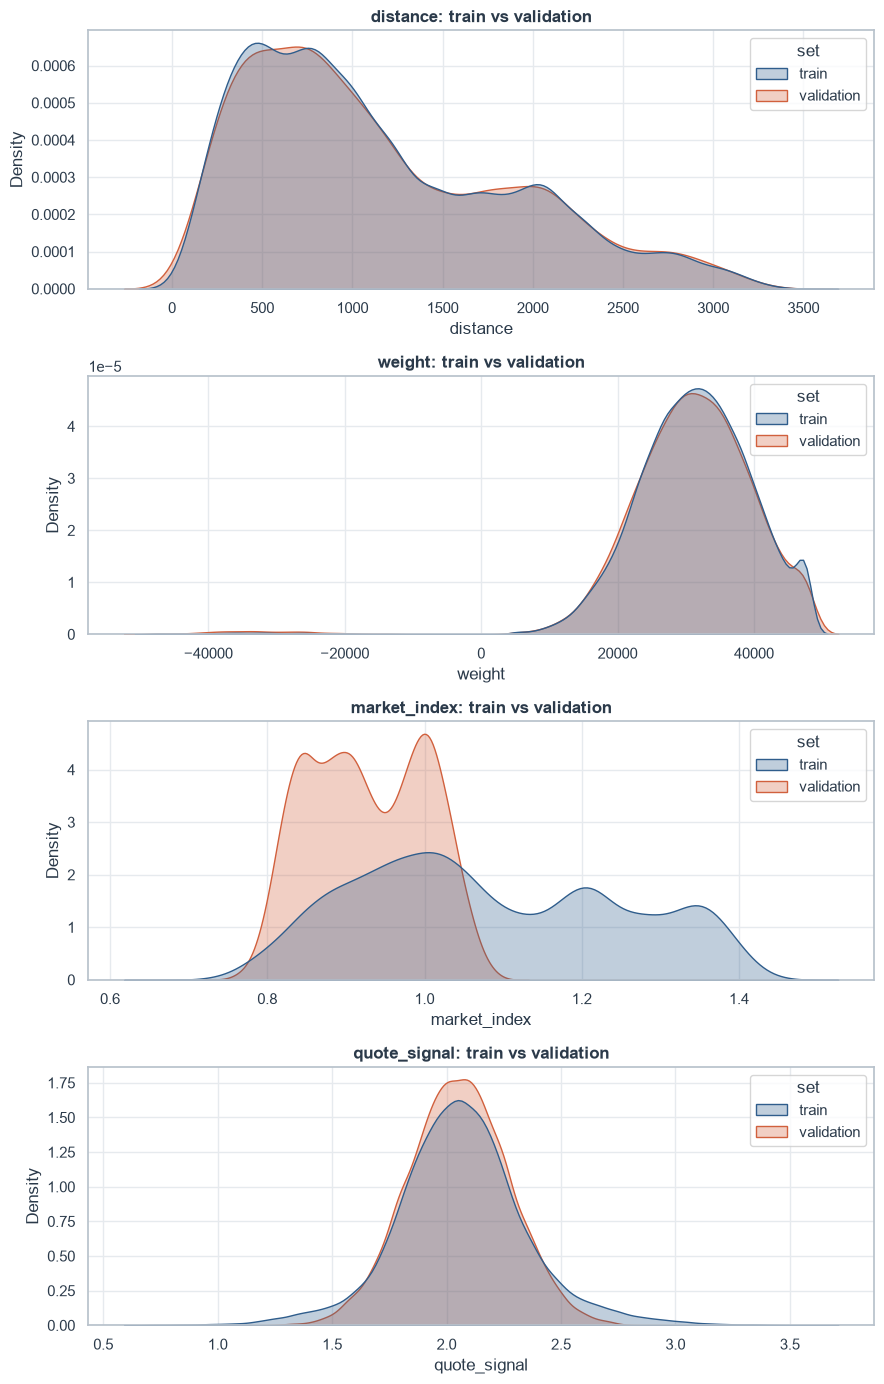

In [27]:
compare = pd.concat([df.assign(set="train"), val.assign(set="validation")], ignore_index=True)
cols = ["distance", "weight", "market_index", "quote_signal"]

fig, axes = plt.subplots(4, 1, figsize=(9, 14))
for ax, col in zip(axes, cols):
    sns.kdeplot(data=compare, x=col, hue="set", common_norm=False,
                palette=[BLUE, CORAL], fill=True, alpha=0.3, ax=ax)
    ax.set_title(f"{col}: train vs validation")

plt.tight_layout()
plt.show()

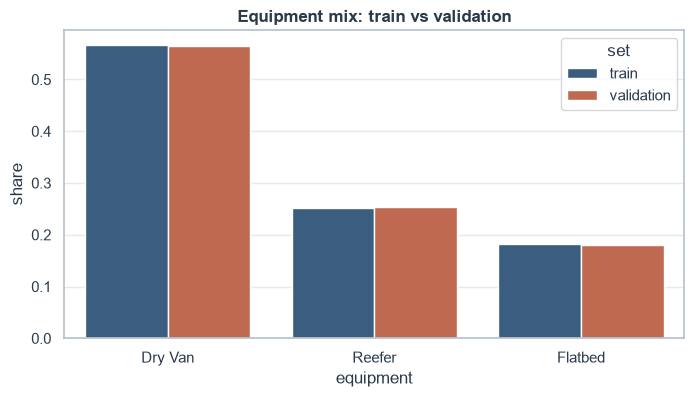

set,train,validation
equipment,,
Dry Van,0.567,0.565
Flatbed,0.182,0.181
Reefer,0.251,0.254


In [28]:
mix = (compare.groupby("set")["equipment"].value_counts(normalize=True)
       .rename("share").reset_index())

plt.figure(figsize=(8, 4))
sns.barplot(data=mix, x="equipment", y="share", hue="set", palette=[BLUE, CORAL])
plt.title("Equipment mix: train vs validation")
plt.show()

mix.pivot(index="equipment", columns="set", values="share").round(3)

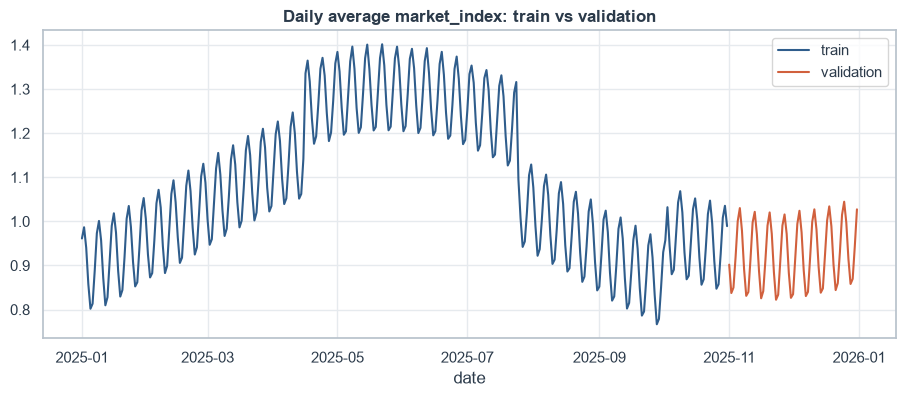

In [29]:
daily_val = val.groupby("date")["market_index"].mean()

plt.figure(figsize=(11, 4))
plt.plot(daily.index, daily["market_index"], color=BLUE, label="train")
plt.plot(daily_val.index, daily_val.values, color=CORAL, label="validation")
plt.title("Daily average market_index: train vs validation")
plt.xlabel("date")
plt.legend()
plt.show()

## Key Insights

- 48,000 loads, Jan 1 to Oct 31, 2025, with every day present (304 days, 115 to 198 loads per day).
- `posted_rate` is the target. `load_id` is an identifier. The categorical columns are `pickup`, `delivery` and `equipment`.

Data quality
- Missing values are small: `market_index` 374 (0.78%) and `weight` 300 (0.62%). Validation has the same issue (249 and 165). I plan to use KNN imputation, fit on training data only.
- `weight` has 292 negative values, with a minimum of -47,500 that mirrors the maximum of +47,500. These look like sign errors. In validation there are 145.
- `weight` is capped at 47,500, and 1,191 loads sit exactly at that value.
- Tukey's rule on rate per mile flags 1,634 loads (3.4%). Many are short hauls, which legitimately have a high rate per mile, so this count overstates the true anomalies. The most extreme loads (12 to 14 $/mile) are genuine spikes that distance and equipment do not explain.

Target
- `posted_rate` is right-skewed (median 2,031, mean 2,374, max 25,533 vs 99th percentile about 5,973). A log transform makes it roughly symmetric.

What drives the rate
- `distance` is by far the strongest driver (correlation 0.91 with `posted_rate`).
- Rate per mile falls as distance grows (correlation -0.33): short hauls earn a premium.
- Equipment matters: median rate per mile is 2.05 (Dry Van), 2.22 (Flatbed) and 2.31 (Reefer).
- `weight`, `market_index` and `quote_signal` have almost no linear correlation with `posted_rate`, but small effects appear against rate per mile (+0.07 to +0.08) once distance is removed.
- No feature pair is redundant by the 0.9 rule. The highest is lat/lon at 0.56.

Time patterns
- `market_index` has a seasonal hump (peak of about 1.4 in May to July, then a sharp fall in late July) plus a weekly cycle that peaks mid-week.
- `quote_signal` shows abrupt level shifts at month boundaries (for example early April, June, July and September).
- Average rate per mile varies only slightly by weekday.

Train vs validation
- Validation covers Nov 1 to Dec 31, entirely after the training period, so the task is forecasting.
- `distance`, `weight`, `quote_signal` and the equipment mix match between the two sets.
- `market_index` has shifted: validation sits between about 0.8 and 1.05, a range training covers mainly in January and September to October.
- Validation contains 8 cities never seen in training (Jackson, Knoxville, Charlotte, Norfolk, Allentown, Chicago, San Diego, Laredo).

Implications for modelling
- Split by time, not randomly, to mimic forecasting into Nov-Dec.
- Don't depend on city names (one-hot or target encoding would fail on unseen cities). Use distance and coordinates instead.
- Fix negative weights before imputing, and fit imputers on training data only.
- Use a log target and a loss that is robust to the extreme spikes.